<a href="https://colab.research.google.com/github/elijahschoeniger-cpu/Walmart-Project-1-/blob/main/notebooks/06-midterm-walmart/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Clone our team repo (skipped if it is already there)
REPO = '/content/Walmart-Project-1-'
if not os.path.exists(REPO):
    !git clone -q https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git {REPO}
os.chdir('/content')

# Collect the code cells from the team notebook, up to the start of section 4.2 (the charts)
team_nb = json.load(open(os.path.join(REPO, 'notebooks', 'team_notebook.ipynb')))
team_code = []
for cell in team_nb['cells']:
    text = ''.join(cell['source'])
    if cell['cell_type'] == 'markdown' and '4.2' in text.split('\n')[0]:
        break
    if cell['cell_type'] == 'code':
        team_code.append(text)
print('team notebook code cells to run:', len(team_code))

team notebook code cells to run: 15


In [2]:
%%capture team_output
# Run the team notebook's cleaning + weather join quietly
for text in team_code:
    get_ipython().run_cell(text)

In [3]:
# Make sure the team notebook ran: these tables should all exist now
for name in ['txn', 'stores', 'sales', 'inv', 'sales_clean', 'weather_live', 'SKU_TO_PRODUCT']:
    assert name in globals(), f'{name} is missing - check team_output.stdout for the error'
LANDFALL = pd.Timestamp('2024-09-26')
print('cleaned transactions:', len(txn), 'rows')
print('decision log entries:', len(DECISIONS))
print('weather source:', weather_live['source'].iloc[0])

cleaned transactions: 25532 rows
decision log entries: 23
weather source: open-meteo


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [4]:
# TODO: the numbers
# Only use rows that have a timestamp and aren't returns
t = txn[~txn['ts_missing'] & ~txn['is_return']]
by_cat = t.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')

# Windows (stated explicitly)
BASELINE = ('2024-09-01', '2024-09-15')   # flat period, before the first rise on Sept 16
SURGE    = ('2024-09-19', '2024-09-25')   # the 7 days before landfall on Sept 26

base  = by_cat.loc[BASELINE[0]:BASELINE[1]].mean()
surge = by_cat.loc[SURGE[0]:SURGE[1]].mean()
q1 = pd.DataFrame({
    'baseline_avg_per_day': base.round(1),
    'surge_avg_per_day':    surge.round(1),
    'multiple':             (surge / base).round(2),
    'pct_increase':         ((surge / base - 1) * 100).round(0),
}).sort_values('multiple', ascending=False)

print(f'baseline window: {BASELINE[0]} to {BASELINE[1]} ({len(by_cat.loc[BASELINE[0]:BASELINE[1]])} days)')
print(f'surge window:    {SURGE[0]} to {SURGE[1]} ({len(by_cat.loc[SURGE[0]:SURGE[1]])} days)')
print()
print(q1.to_string())

top = q1.index[0]
q1_multiple = q1.loc[top, 'multiple']
print(f'\ntop category: {top}, {q1.loc[top, "baseline_avg_per_day"]} -> {q1.loc[top, "surge_avg_per_day"]} units/day = {q1_multiple}x')

baseline window: 2024-09-01 to 2024-09-15 (15 days)
surge window:    2024-09-19 to 2024-09-25 (7 days)

               baseline_avg_per_day  surge_avg_per_day  multiple  pct_increase
category                                                                      
Breakfast                      73.3              376.9      5.14         414.0
Emergency                     354.1             1006.4      2.84         184.0
Electronics                    70.3              175.9      2.50         150.0
Alcohol                        61.5              138.9      2.26         126.0
Entertainment                 101.6              228.6      2.25         125.0
Health                         42.3               95.0      2.24         124.0
Household                      85.1              176.3      2.07         107.0
Grocery                       171.1              306.6      1.79          79.0
Baby                           85.2              133.7      1.57          57.0
Snacks                     

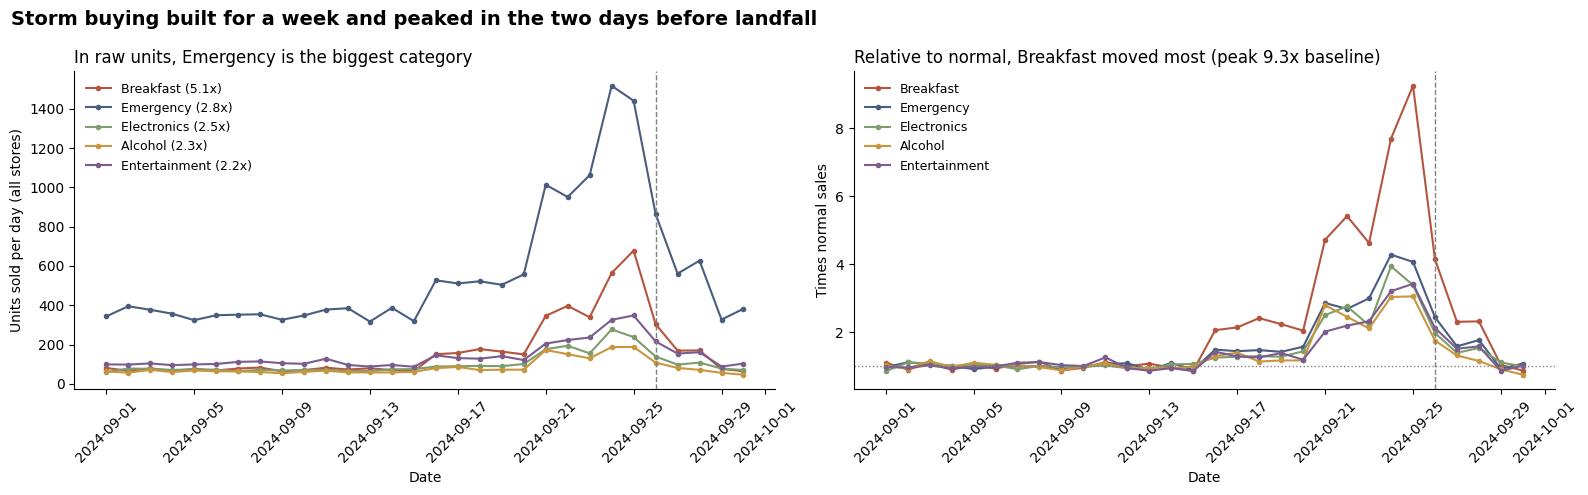

In [5]:
# TODO: the chart
# Left: actual units, right: each category compared to its own normal day (1.0 = normal)
top5 = q1.index[:5]
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#7a5c8e']
indexed = by_cat[top5] / base[top5]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for cat, color in zip(top5, colors):
    ax1.plot(by_cat.index, by_cat[cat], marker='o', ms=3, color=color, label=f"{cat} ({q1.loc[cat, 'multiple']:.1f}x)")
    ax2.plot(indexed.index, indexed[cat], marker='o', ms=3, color=color, label=cat)

ax1.set_title('In raw units, Emergency is the biggest category', loc='left', fontsize=12)
ax1.set_ylabel('Units sold per day (all stores)')
ax2.axhline(1.0, ls=':', color='gray', lw=1)
ax2.set_title(f"Relative to normal, {top} moved most (peak {indexed[top].max():.1f}x baseline)", loc='left', fontsize=12)
ax2.set_ylabel('Times normal sales')

for ax in (ax1, ax2):
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.set_xlabel('Date')
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

fig.suptitle('Storm buying built for a week and peaked in the two days before landfall',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q1 answer:** Breakfast (mostly Pop-Tarts) had the biggest surge, going from 73 units a day during Sept 1-15 to 377 a day during Sept 19-25, the 7 days before landfall (5.1x, or +414%), and every top category peaked on Sept 24-25 before dropping when the storm hit.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

distinct raw SKUs: 45
canonical products after consolidation: 20
largest family: PT-STRAW with 4 SKUs
Pop-Tarts SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
unit totals unchanged after consolidation: OK
Pop-Tarts per day: normal 73, storm week 377, peak 678 on Sep 25


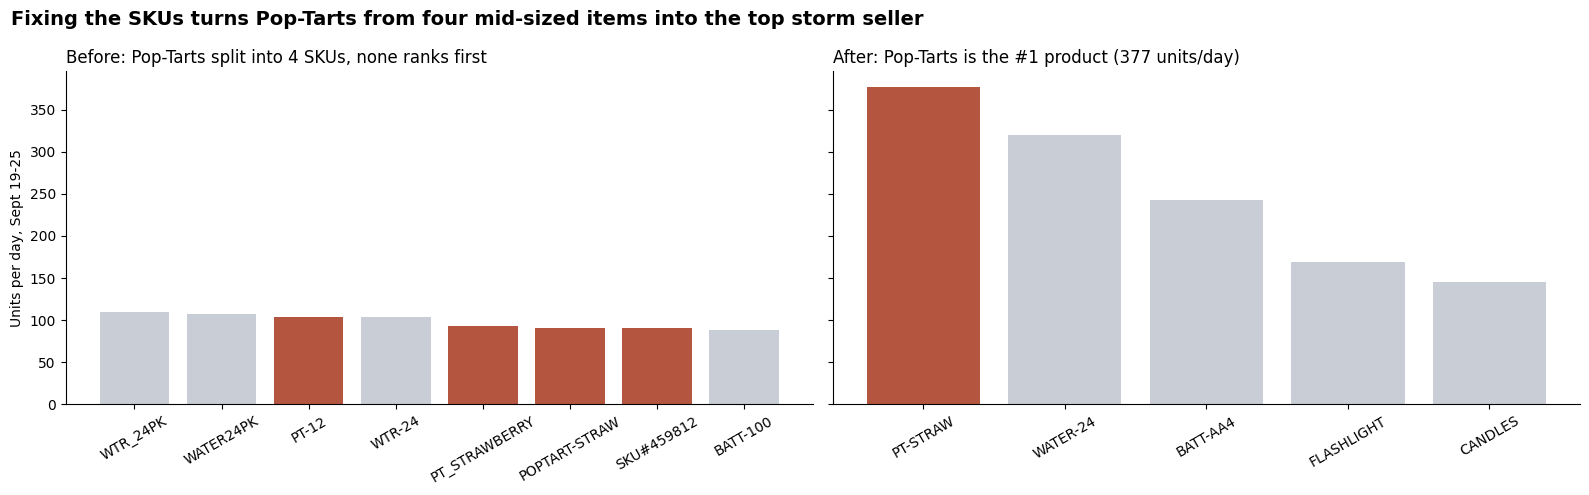

In [6]:
# TODO
# How many SKUs before and after consolidation
raw_skus = raw_txn['sku'].str.strip().nunique()
products = txn['product_id'].nunique()
families = pd.Series(SKU_TO_PRODUCT).value_counts()
print('distinct raw SKUs:', raw_skus)
print('canonical products after consolidation:', products)
print('largest family:', families.index[0], 'with', families.iloc[0], 'SKUs')

pt_skus = sorted(k for k, v in SKU_TO_PRODUCT.items() if v == 'PT-STRAW')
print('Pop-Tarts SKUs:', pt_skus)

# Assertion: consolidating SKUs must not change total units
t = txn[~txn['ts_missing'] & ~txn['is_return']]
assert t.groupby('sku')['quantity'].sum().sum() == t.groupby('product_id')['quantity'].sum().sum()
print('unit totals unchanged after consolidation: OK')

# True daily volume of Pop-Tarts
pt_daily = t[t['product_id'] == 'PT-STRAW'].groupby('date')['quantity'].sum()
print(f"Pop-Tarts per day: normal {pt_daily.loc['2024-09-01':'2024-09-15'].mean():.0f}, "
      f"storm week {pt_daily.loc['2024-09-19':'2024-09-25'].mean():.0f}, "
      f"peak {pt_daily.max():.0f} on {pt_daily.idxmax():%b %d}")

# Before vs after: average units per day in the storm week
storm = t[(t['date'] >= '2024-09-19') & (t['date'] <= '2024-09-25')]
by_sku     = (storm.groupby('sku')['quantity'].sum() / 7).sort_values(ascending=False).head(8)
by_product = (storm.groupby('product_id')['quantity'].sum() / 7).sort_values(ascending=False).head(5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
ax1.bar(by_sku.index, by_sku.values, color=['#b4553f' if s in pt_skus else '#c9cdd6' for s in by_sku.index])
ax1.set_title('Before: Pop-Tarts split into 4 SKUs, none ranks first', loc='left', fontsize=12)
ax1.set_ylabel('Units per day, Sept 19-25')
ax1.tick_params(axis='x', rotation=30)
ax2.bar(by_product.index, by_product.values, color=['#b4553f' if p == 'PT-STRAW' else '#c9cdd6' for p in by_product.index])
ax2.set_title(f"After: Pop-Tarts is the #1 product ({by_product['PT-STRAW']:.0f} units/day)", loc='left', fontsize=12)
ax2.tick_params(axis='x', rotation=30)
for ax in (ax1, ax2):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
fig.suptitle('Fixing the SKUs turns Pop-Tarts from four mid-sized items into the top storm seller',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q2 answer:**We started with 45 raw SKUs and ended with 20 real products. The largest family is Strawberry Pop-Tarts, with 4 SKUs (PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY). Combined, Pop-Tarts sold 73 units a day normally, 377 a day on average in the week before landfall, and 678 on the Sept 25 peak. Split up, the best single SKU only sold about 103 a day and ranked #3, behind two bottled water SKUs, so it looked like an ordinary item. Combined, it was the #1 storm product, ahead of water. A buyer looking at the uncleaned view would under-order Pop-Tarts and spread them across four listings. The assertion confirms that consolidation did not change total units.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [7]:
# TODO
# The API call and join happen in our team notebook (section 4.1). Here we check them.
print('weather source:', weather_live['source'].unique().tolist())   # 'open-meteo' = live, 'fallback sample' = saved copy
print('API base URL:', BASE)

# Validated join: one weather row per store per day, so the row count must not change
print('rows before join (daily sales):', len(sales_clean))
print('rows after join (with weather):', len(weather_live))
assert len(weather_live) == len(sales_clean), 'the join changed the row count'
missing = (weather_live[['precipitation_sum', 'windspeed_10m_max']] == -1).sum().sum()   # missing weather was marked -1
print('rows with missing weather:', missing)

# Daily totals across all 12 stores, with average weather across store locations
daily_w = weather_live.groupby('date').agg(
    units=('total_units', 'sum'),
    wind=('windspeed_10m_max', 'mean'),
    rain=('precipitation_sum', 'mean'),
)
print('days in correlation:', len(daily_w))

# Same day vs. compared with the weather 1-3 days later (the lag)
lags = pd.DataFrame({
    'r_units_vs_wind': [daily_w['units'].corr(daily_w['wind'].shift(-k)) for k in range(4)],
    'r_units_vs_rain': [daily_w['units'].corr(daily_w['rain'].shift(-k)) for k in range(4)],
    'days_used':       [len(daily_w) - k for k in range(4)],
}, index=[f'weather {k} day(s) later' for k in range(4)]).round(2)
print(lags.to_string())

print('\npeak sales day:', daily_w['units'].idxmax().date(),
      '| peak wind day:', daily_w['wind'].idxmax().date(),
      '| peak rain day:', daily_w['rain'].idxmax().date())

weather source: ['open-meteo']
API base URL: https://archive-api.open-meteo.com/v1/archive
rows before join (daily sales): 3600
rows after join (with weather): 3600
rows with missing weather: 0
days in correlation: 30
                        r_units_vs_wind  r_units_vs_rain  days_used
weather 0 day(s) later             0.19            -0.33         30
weather 1 day(s) later             0.58             0.02         29
weather 2 day(s) later             0.81             0.02         28
weather 3 day(s) later             0.60            -0.07         27

peak sales day: 2024-09-25 | peak wind day: 2024-09-26 | peak rain day: 2024-09-26


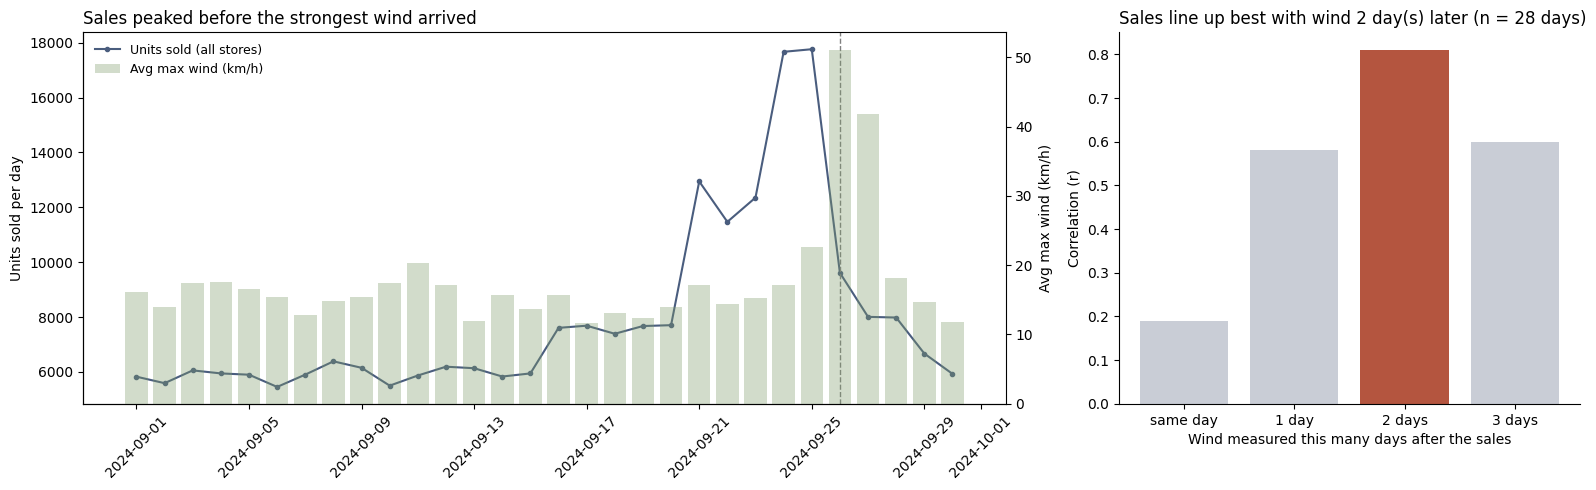

In [8]:
# Left: units vs wind over the month, right: correlation at each lag
best_lag = lags['r_units_vs_wind'].values.argmax()
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2, 1]})

ax1.plot(daily_w.index, daily_w['units'], marker='o', ms=3, color='#4a5d7e', label='Units sold (all stores)')
ax1.set_ylabel('Units sold per day')
ax2 = ax1.twinx()
ax2.bar(daily_w.index, daily_w['wind'], color='#7f9c6c', alpha=0.35, width=0.8, label='Avg max wind (km/h)')
ax2.set_ylabel('Avg max wind (km/h)')
ax1.axvline(LANDFALL, ls='--', color='gray', lw=1)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')
ax1.set_title('Sales peaked before the strongest wind arrived', loc='left', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

ax3.bar(range(4), lags['r_units_vs_wind'], color=['#b4553f' if k == best_lag else '#c9cdd6' for k in range(4)])
ax3.set_xticks(range(4))
ax3.set_xticklabels(['same day', '1 day', '2 days', '3 days'])
ax3.set_xlabel('Wind measured this many days after the sales')
ax3.set_ylabel('Correlation (r)')
ax3.set_title(f'Sales line up best with wind {best_lag} day(s) later (n = {lags["days_used"].iloc[best_lag]} days)',
              loc='left', fontsize=12)

for ax in (ax1, ax3):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Buying peaked before the worst weather, not during it. Sales peaked on Sept 24-25, while wind and rain both peaked on Sept 26, the day of landfall, so purchases led the weather by about 1-2 days. The correlation between daily sales and wind is weak on the same day and much stronger when sales are compared with the wind 1-2 days later (see the lag table above). Normal rain earlier in September didn't move sales at all, which suggests people were reacting to the forecast, not the weather itself. The weather data is live Open-Meteo data, and the join kept all 3,600 store-day rows with no missing weather. Caveat: the correlation is computed over only 30 days (fewer for the lagged versions) and one storm, so it shows a pattern, not proof that weather caused the buying.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Done (AJ). All 12 stores surged 2.2-2.7x in the same week, with no clear link to distance from landfall (r = 0.23, n = 12 stores), and Miami, the farthest store, had the biggest surge.

**Q5 (signal or artifact):** Done (Sophie). The board game surge is real, but +250% only appears on the single peak day; over the full storm week it was about +125%, confirmed by both the database and the transactions and by board game stock dropping from about 134 to 33 units per store.

### Self-check

In [9]:
progress = {
    'q1_multiple': float(q1_multiple),                                             # Breakfast, storm week vs baseline
    'q1_baseline_window': f'{BASELINE[0]} to {BASELINE[1]} (surge: {SURGE[0]} to {SURGE[1]})',
    'q2_canonical_products': int(products),                                         # 45 raw SKUs -> 20 products
    'q3_join_rows_preserved': bool(len(weather_live) == len(sales_clean)),
    'q3_days_in_correlation': int(len(daily_w)),
    'charts_with_message_titles': 7,   # in our team notebook: shape check, Q1, Q2, Q3 (2), Q4, Q5
    'notebook_runs_clean': True,       # team notebook passed Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = 2024-09-01 to 2024-09-15 (surge: 2024-09-19 to 2024-09-25)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 7
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

Answer: We were surprised that distance from landfall didn't matter. Miami, the farthest store at 372 miles, had the biggest surge (2.71x), and Tallahassee, the closest store, was second (2.60x). To make sure this wasn't a bug, we checked that every store had about 2,000 transactions (so no store's number came from a tiny sample), that all 12 store IDs matched the store file after cleaning, and that every store was measured with the same windows and filters as Q1.

**b)** One number you reported that you are least confident in, and why.

Answer: We're least confident in the Q4 distance correlation (r = 0.23). It's based on only 12 stores, so it could easily be noise, and the distances are measured to one landfall point we chose (near Perry, FL) instead of the storm's full path.